<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 📊 M2 Lab 2 · 给研究 crew 加自定义画图工具

**一句话**：接着 Lab 1 的 crew，写一个 `BaseTool` 子类 `CustomPlotTool`：从核查过的资料里抽数据、自动画图，交给 Report Writer 插进报告。

<span style="display:inline-block; background:rgba(15,23,42,0.55); border:1px solid rgba(147,197,253,0.4); color:#e0e7ff; padding:2px 10px; border-radius:999px; font-size:0.82em; margin:2px 6px 2px 0;">🏷️ Lab</span><span style="display:inline-block; background:rgba(15,23,42,0.55); border:1px solid rgba(147,197,253,0.4); color:#e0e7ff; padding:2px 10px; border-radius:999px; font-size:0.82em; margin:2px 6px 2px 0;">📄 C1M2_Lab_2_deep_research_p2.ipynb</span><span style="display:inline-block; background:rgba(15,23,42,0.55); border:1px solid rgba(147,197,253,0.4); color:#e0e7ff; padding:2px 10px; border-radius:999px; font-size:0.82em; margin:2px 6px 2px 0;">🧩 前置：M2 Lab 1（guardrail / hook / memory） · tool_function_vs_tool_class.ipynb</span><span style="display:inline-block; background:rgba(15,23,42,0.55); border:1px solid rgba(147,197,253,0.4); color:#e0e7ff; padding:2px 10px; border-radius:999px; font-size:0.82em; margin:2px 6px 2px 0;">🧩 config/agents.yaml · config/tasks.yaml · utils.py</span>

</div>

<div class="dark-info" style="background:#1e293b; color:#e2e8f0; padding:12px 24px; border-left:4px solid #60a5fa; border-radius:4px; width:97%;"><style>.dark-info strong{color:#fbbf24;}</style>

**要解决的问题**：报告光有文字不够直观，要自动配图。
做法：给 **Report Writer** 一个自定义工具——输入「整段研究文本」，工具内部让 LLM 找出可量化的数据，用 seaborn 画图存成 PNG，返回图片路径；writer 再把路径用 Markdown 图片语法写进报告。

本 lab 需要你写的：① `CustomPlotTool` 的 `name` / `description` / `_run` 签名；② 把工具交给 report_writer；③ 改 `tasks.yaml` 里 `write_final_report` 的说明，让 writer 真的去用工具、把图放进报告；④ `user_query`。其余（guardrail / hook / crew）沿用 Lab 1 的答案。

</div>

<img src="./images/lab2-agents-tasks-diagram.png" width="900">

| agent | 负责的 task | 工具 | 输出交给谁 |
|---|---|---|---|
| Research Planner | `create_research_plan`：拆成研究主题 + 关键问题 + 成功标准 | 无 | Internet Researcher |
| Internet Researcher | `gather_research_data`：搜索 + 抓取网页，带引用 | `EXASearchTool` `ScrapeWebsiteTool` | Fact Checker |
| Fact Checker | `verify_information_quality`：交叉验证、标出可疑信息与缺口 | 同上 | Report Writer |
| Report Writer | `write_final_report`：写最终报告（摘要 / 发现 / 证据 / 引用 / 建议） | 无（Lab 2 加画图工具） | `after_kickoff` hook 存文件 |

默认 `process=sequential`：task 按列表顺序执行，**前面所有 task 的输出自动作为后面 task 的 context**，所以 tasks.yaml 里不用写 `context`。

<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:6px 20px; border-radius:6px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

### 🛠️ 第 1 步：导入 + 环境变量

</div>

<div style="width:97%;"><div style="display:grid; grid-template-columns:repeat(auto-fit,minmax(230px,1fr)); gap:10px;"><div style="background:#1e293b; border:1px solid #334155; border-top:3px solid #60a5fa; border-radius:8px; padding:10px 14px; color:#e2e8f0;"><div style="font-weight:700; color:#fde047; margin-bottom:4px;">🔑 <code style="background:#0b1220; color:#fde68a; padding:1px 5px; border-radius:4px; font-size:0.92em;">utils.get_*_api_key()</code></div><div style="font-size:0.92em; line-height:1.6;"><code style="background:#0b1220; color:#fde68a; padding:1px 5px; border-radius:4px; font-size:0.92em;">load_dotenv(find_dotenv())</code>：从当前目录往上找 <code style="background:#0b1220; color:#fde68a; padding:1px 5px; border-radius:4px; font-size:0.92em;">.env</code>（找到仓库根的那份），再读环境变量。</div></div><div style="background:#1e293b; border:1px solid #334155; border-top:3px solid #4ade80; border-radius:8px; padding:10px 14px; color:#e2e8f0;"><div style="font-weight:700; color:#fde047; margin-bottom:4px;">🤖 <code style="background:#0b1220; color:#fde68a; padding:1px 5px; border-radius:4px; font-size:0.92em;">os.environ[&quot;MODEL&quot;]</code></div><div style="font-size:0.92em; line-height:1.6;">没给 agent 传 <code style="background:#0b1220; color:#fde68a; padding:1px 5px; border-radius:4px; font-size:0.92em;">llm=</code> 时，CrewAI 用 <code style="background:#0b1220; color:#fde68a; padding:1px 5px; border-radius:4px; font-size:0.92em;">MODEL</code> 环境变量当默认模型（不设则用 crewai 内置默认，1.15.22 是 <code style="background:#0b1220; color:#fde68a; padding:1px 5px; border-radius:4px; font-size:0.92em;">gpt-4.1-mini</code>）。</div></div><div style="background:#1e293b; border:1px solid #334155; border-top:3px solid #fbbf24; border-radius:8px; padding:10px 14px; color:#e2e8f0;"><div style="font-weight:700; color:#fde047; margin-bottom:4px;">🧪 <code style="background:#0b1220; color:#fde68a; padding:1px 5px; border-radius:4px; font-size:0.92em;">CREWAI_TESTING=true</code></div><div style="font-size:0.92em; line-height:1.6;">让 crewai 认为处于测试环境：<b>跳过首次运行时「是否开启 tracing」的交互确认</b>，notebook 不会卡住等输入。</div></div></div></div>

In [1]:
from crewai import Agent, Task, Crew, LLM
from crewai_tools import EXASearchTool, ScrapeWebsiteTool
import os
os.environ["CREWAI_TESTING"] = "true"   # 跳过首次运行的 tracing 交互确认
from utils import get_openai_api_key, get_exa_api_key
from IPython.display import Markdown
import yaml

# set the OpenAI model (gpt-4o-mini)
os.environ["MODEL"] = "gpt-4o-mini"   # 没指定 llm 的 agent 默认用它
# set up the OpenAI API key 
os.environ["OPENAI_API_KEY"] = get_openai_api_key()
# set the exa API key
os.environ["EXA_API_KEY"] = get_exa_api_key()

<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:6px 20px; border-radius:6px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

### 🧠 自定义工具 = 模型能读懂的「说明书」+ 一个 Python 函数

</div>

<div style="width:97%;"><div style="display:grid; grid-template-columns:repeat(auto-fit,minmax(230px,1fr)); gap:10px;"><div style="background:#1e293b; border:1px solid #334155; border-top:3px solid #60a5fa; border-radius:8px; padding:10px 14px; color:#e2e8f0;"><div style="font-weight:700; color:#fde047; margin-bottom:4px;">🏷️ name</div><div style="font-size:0.92em; line-height:1.6;">工具名，模型调用时用它指代工具。</div></div><div style="background:#1e293b; border:1px solid #334155; border-top:3px solid #fbbf24; border-radius:8px; padding:10px 14px; color:#e2e8f0;"><div style="font-weight:700; color:#fde047; margin-bottom:4px;">📝 description</div><div style="font-size:0.92em; line-height:1.6;"><b>最关键</b>：模型只靠它决定「什么时候用、传什么」。<br>要写清：期望输入（完整的、核查过的研究文本，字符串）+ 作用（从文本自动生成图）。</div></div><div style="background:#1e293b; border:1px solid #334155; border-top:3px solid #a78bfa; border-radius:8px; padding:10px 14px; color:#e2e8f0;"><div style="font-weight:700; color:#fde047; margin-bottom:4px;">🧾 args_schema</div><div style="font-size:0.92em; line-height:1.6;">参数的 Pydantic 模型。<br>不写时 crewai 从 <code style="background:#0b1220; color:#fde68a; padding:1px 5px; border-radius:4px; font-size:0.92em;">_run</code> 的签名 <b>自动推断</b>（这里 → <code style="background:#0b1220; color:#fde68a; padding:1px 5px; border-radius:4px; font-size:0.92em;">{research: str}</code>）。</div></div><div style="background:#1e293b; border:1px solid #334155; border-top:3px solid #4ade80; border-radius:8px; padding:10px 14px; color:#e2e8f0;"><div style="font-weight:700; color:#fde047; margin-bottom:4px;">⚙️ _run(...)</div><div style="font-size:0.92em; line-height:1.6;">真正执行的逻辑；返回值（字符串）就是模型看到的工具结果。</div></div></div></div>

课程给的模板：
```python
class MyCustomTool(BaseTool):
    name: str = "Name of my tool"
    description: str = "What this tool does. It's vital for effective utilization."
    args_schema: Type[BaseModel] = {}      # ⚠️ 模板写法不严谨：应是一个 BaseModel 子类；不需要时干脆省略
    def _run(self, argument: str) -> str:
        return "Tool's result"
```
`@tool` 函数写法 vs `BaseTool` 类写法的完整对比，见同目录的 `tool_function_vs_tool_class.ipynb`。

<div style="background:#111827; border:1px dashed #334155; border-radius:8px; padding:10px 16px; width:97%;"><div style="color:#94a3b8; font-weight:700; margin-bottom:6px;">CustomPlotTool 一次调用的全过程</div><span style="display:inline-block; background:#0f172a; border:1.5px solid #a78bfa; color:#e2e8f0; padding:4px 12px; border-radius:999px; margin:3px 0; font-size:0.9em;">writer 调用工具，传入 <code style="background:#0b1220; color:#fde68a; padding:1px 5px; border-radius:4px; font-size:0.92em;">research</code></span><span style="color:#fbbf24; margin:0 6px; font-weight:700;">➜</span><span style="display:inline-block; background:#0f172a; border:1.5px solid #fbbf24; color:#e2e8f0; padding:4px 12px; border-radius:999px; margin:3px 0; font-size:0.9em;">内部 LLM 抽数据 → JSON</span><span style="color:#fbbf24; margin:0 6px; font-weight:700;">➜</span><span style="display:inline-block; background:#0f172a; border:1.5px solid #60a5fa; color:#e2e8f0; padding:4px 12px; border-radius:999px; margin:3px 0; font-size:0.9em;">pandas + seaborn 画图</span><span style="color:#fbbf24; margin:0 6px; font-weight:700;">➜</span><span style="display:inline-block; background:#0f172a; border:1.5px solid #4ade80; color:#e2e8f0; padding:4px 12px; border-radius:999px; margin:3px 0; font-size:0.9em;">存 <code style="background:#0b1220; color:#fde68a; padding:1px 5px; border-radius:4px; font-size:0.92em;">plots/plot_N_时间戳.png</code></span><span style="color:#fbbf24; margin:0 6px; font-weight:700;">➜</span><span style="display:inline-block; background:#0f172a; border:1.5px solid #4ade80; color:#e2e8f0; padding:4px 12px; border-radius:999px; margin:3px 0; font-size:0.9em;">返回 "Successfully created N plots: 路径..."</span><span style="color:#fbbf24; margin:0 6px; font-weight:700;">➜</span><span style="display:inline-block; background:#0f172a; border:1.5px solid #a78bfa; color:#e2e8f0; padding:4px 12px; border-radius:999px; margin:3px 0; font-size:0.9em;">writer 用 <code style="background:#0b1220; color:#fde68a; padding:1px 5px; border-radius:4px; font-size:0.92em;">![](路径)</code> 写进报告</span></div>

<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:6px 20px; border-radius:6px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

### 🛠️ 第 2 步：写 CustomPlotTool

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

📝 **你填的部分**：`name`、`description`（说明了输入是完整的已核查信息、作用是从文本自动生成图）、`_run(self, research: str) -> str`——正确，与 Solution 一致。画图逻辑是课程给定的。

</div>

In [2]:
# import packages needed for the custom tool
from crewai.tools import BaseTool
from crewai import LLM
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import json


# Define the custom tool for creating plots
class CustomPlotTool(BaseTool):   # 继承 BaseTool = 面向对象写法的自定义工具
    ### START CODE HERE ###
    name: str = "Create custom plots"   # 模型看到的工具名
    description: str = (   # 模型据此判断「何时调用、传什么」——写清输入和作用
        "This a tool for automatically creating custom plots based on a research result. "
        "This tools automatically generates the plots from a text input, which should have fact checked information. "
        "Pass the full validated information gathered so far as a string."
    )

    def _run(self, research: str) -> str:   # 参数签名 → 自动生成 args_schema {research: str}
        ### END CODE HERE ###
        try:   # ① 先用下面的 prompt 让 LLM 从研究文本里抽出「可画图的数据」
            extraction_prompt = f"""
            You are an expert data visualization assistant. Analyze the provided research text and identify meaningful, insightful charts that can be created to visualize quantifiable data supporting the research's key insights and findings. Only suggest charts for data that includes numerical values, measurable trends, comparisons, or categorical distributions that can be effectively plotted.

            Focus on creating visualizations that highlight trends, comparisons, distributions, or relationships that add value to the research. Avoid suggesting charts for purely qualitative or non-quantifiable information.

            For each chart, provide a JSON object with:
              - "chart_type" (string: choose from "line" for trends over time/continuous, "bar" for comparisons, "histogram" for distributions, "scatter" for relationships, "pie" for proportions)
              - "x_axis" (string: variable name for x-axis, e.g., "year", "category")
              - "y_axis" (string: variable name for y-axis, e.g., "value", "count")
              - "color" (string: optional variable for color grouping/hue, or null if not applicable)
              - "Title" (string: descriptive, insightful title that explains what the chart shows)
              - "data" (dictionary: keys matching x_axis, y_axis, and color variables; values as lists of extracted numerical/categorical data from the research)

            Ensure data is accurately extracted and formatted as lists. If a variable has multiple series (e.g., for color), include all in the data dictionary.

            If no quantifiable data suitable for meaningful visualization is present in the research, return an empty array [].

            Text:
            {research}

            Example output (return valid JSON only):
            [
              {{"chart_type": "line", "x_axis": "year", "y_axis": "funding_amount", "color": "sector", "Title": "AI Research Funding Trends by Sector", "data": {{"year": [2020, 2021, 2022], "funding_amount": [2.5, 3.8, 5.2], "sector": ["Healthcare", "Finance", "Tech"]}}}},
              {{"chart_type": "bar", "x_axis": "tool_name", "y_axis": "adoption_rate", "color": null, "Title": "Market Adoption Rates of AI Tools", "data": {{"tool_name": ["ToolA", "ToolB", "ToolC"], "adoption_rate": [45, 67, 23]}}}}
            ]

            Return only the JSON array, no additional text or explanations.
            """
            llm = LLM(
                model="gpt-4o-mini",   # 工具内部自己又调了一次 LLM（独立于 agent 的 LLM）
            )  # Initialize the LLM instance
            llm_response = llm.call([{"role": "user", "content": extraction_prompt}])   # 同步调用，返回字符串

            # Clean the response to extract just the JSON part
            llm_response = llm_response.strip()
            if llm_response.startswith("```json"):   # 去掉模型可能包的 ```json 代码块围栏
                llm_response = llm_response[7:]  # Remove ```json
            if llm_response.endswith("```"):
                llm_response = llm_response[:-3]  # Remove ```
            llm_response = llm_response.strip()

            # --- Step 2: Parse the LLM output ---
            charts_data = json.loads(llm_response)   # ② 解析成 list[dict]，每个 dict 描述一张图

            if not isinstance(charts_data, list) or len(charts_data) == 0:
                return "No information found in the research to visualize."

            plots_created = []

            # --- Step 3: Create plots for each chart ---
            for i, chart_info in enumerate(charts_data):
                try:
                    # Extract chart configuration
                    chart_type = chart_info.get("chart_type", None).lower()
                    x_axis = chart_info.get("x_axis", "x")
                    y_axis = chart_info.get("y_axis", "y")
                    title = chart_info.get("Title", f"Chart {i + 1}")
                    hue = chart_info.get("color", None)
                    data = chart_info.get("data", {})

                    # Create DataFrame from the data
                    df = pd.DataFrame(data)   # ③ 每张图的数据 → DataFrame → seaborn 画图

                    if df.empty:
                        continue

                    # Create the plot
                    plt.figure(figsize=(10, 6))

                    if chart_type == "line":
                        sns.lineplot(data=df, x=x_axis, y=y_axis, marker="o", hue=hue)
                    elif chart_type in ["bar", "column"]:
                        sns.barplot(data=df, x=x_axis, y=y_axis, hue=hue)
                    elif chart_type == "histogram":
                        plt.hist(df[y_axis], bins=10, alpha=0.7, hue=hue)   # ⚠️ 课程 bug：plt.hist 没有 hue 参数，直方图必然报错（被下面 except 吞掉）
                        plt.xlabel(y_axis)
                        plt.ylabel("Frequency")
                    elif chart_type == "scatter":
                        # Default to scatter plot
                        sns.scatterplot(data=df, x=x_axis, y=y_axis, hue=hue)
                    elif chart_type == "pie":
                        # For pie chart, assume y_axis is values, x_axis is labels
                        plt.pie(
                            df[y_axis],
                            labels=df[x_axis],
                            autopct="%1.1f%%",
                            startangle=90,
                        )
                        plt.title(title)
                        plt.axis(
                            "equal"
                        )  # Equal aspect ratio ensures that pie is drawn as a circle.

                    plt.title(title)
                    plt.xticks(rotation=45)
                    plt.tight_layout()

                    # --- Step 4: Save the plot ---
                    os.makedirs("plots", exist_ok=True)   # ④ 存到 cwd 下的 plots/
                    filename = f"plots/plot_{i + 1}_{datetime.now().strftime('%Y%m%d_%H%M%S')}.png"
                    plt.savefig(filename, dpi=300, bbox_inches="tight")
                    plt.close()   # 关闭图，避免内存累积、也不会在 notebook 里弹出

                    plots_created.append(filename)

                except Exception as e:
                    print(f"Error creating chart {i + 1}: {str(e)}")
                    continue

            if plots_created:
                return f"Successfully created {len(plots_created)} plots: {', '.join(plots_created)}"   # ⑤ 返回给 agent 的只是一段文字：图的文件路径
            else:
                return "No plots could be created from the extracted data."

        except json.JSONDecodeError as e:   # 工具出错时返回字符串而不是抛异常 → agent 能读到并继续
            return f"Error parsing LLM response as JSON: {str(e)}"
        except Exception as e:
            return f"Error generating smart plot: {str(e)}"

不跑 crew 也能单独测试工具：`BaseTool` 实例有 `.run(**kwargs)`。下面用一小段带数字的文本试一下（会调用一次 gpt-4o-mini，生成 1–2 张图）：

In [3]:
demo = CustomPlotTool()
print(demo.args_schema.model_json_schema()["properties"])   # 自动推断出的参数：{'research': {...}}
print(demo.run(research="Tool adoption in 2025: ToolA 45%, ToolB 67%, ToolC 23%. "
                        "Monthly price: ToolA $99, ToolB $249, ToolC $49."))

{'research': {'title': 'Research', 'type': 'string'}}


Successfully created 2 plots: plots/plot_1_20261021_225653.png, plots/plot_2_20261021_225653.png


<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:6px 20px; border-radius:6px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

### 🛠️ 第 3 步：搜索 / 抓取工具（同 Lab 1）

</div>

Internet Researcher 和 Fact Checker 仍然用 Exa 搜索 + 网页抓取。

In [4]:
# create tools instances
exa_search_tool = EXASearchTool(base_url=os.getenv("EXA_BASE_URL"))   # deprecated 别名（新名 ExaSearchTool），仍可用；EXA_BASE_URL 本地未设 → 直连 Exa
scrape_website_tool = ScrapeWebsiteTool()

/var/folders/xx/ypnl5f2n0y7b48w_pgxyhqt80000gn/T/ipykernel_35923/882066312.py:2: DeprecationWarning: EXASearchTool is deprecated and will be removed in a future release; use ExaSearchTool instead.
  exa_search_tool = EXASearchTool(base_url=os.getenv("EXA_BASE_URL"))   # deprecated 别名（新名 ExaSearchTool），仍可用；EXA_BASE_URL 本地未设 → 直连 Exa


<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:6px 20px; border-radius:6px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

### 🛠️ 第 4 步：4 个 agent —— 画图工具给 Report Writer

</div>

<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:6px 20px; border-radius:6px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

### 📄 配置文件：`config/agents.yaml` 与 `config/tasks.yaml`

</div>

agent 的 `role / goal / backstory` 和 task 的 `description / expected_output` 都写在 YAML 里，Python 只负责「装配」：

| 文件 | 顶层 key | 每个 key 下的字段 | Python 里怎么用 |
|---|---|---|---|
| `agents.yaml` | `research_planner` `internet_researcher` `fact_checker` `report_writer` | `role` `goal` `backstory` | `Agent(config=agent_config["research_planner"], ...)` |
| `tasks.yaml` | `create_research_plan` `gather_research_data` `verify_information_quality` `write_final_report` | `description` `expected_output` | `Task(config=task_config["..."], agent=...)` |

- `config=` 字典里的字段等价于直接写 `Agent(role=..., goal=...)`；工具、`verbose`、agent 绑定等 **运行时对象** YAML 表达不了，所以在 Python 里补。
- `{user_query}` 是占位符：`kickoff(inputs={"user_query": ...})` 时被替换进 **所有** agent / task 文本。
- YAML 语法：`'...'` 单引号字符串和 `>` 折叠块都可以跨行，换行会被折成空格。

两个课程视频里没讲、lab 里加上的参数（都是为了跑得快、别撞限流）：
- `max_rpm=150`：该 agent 每分钟最多 150 次 LLM 请求，超了自动等待；
- `max_iter=15`：思考↔调工具 最多 15 轮（默认 25），到上限必须给出「当前最好答案」。

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

📝 **你填的部分**：`report_writer` 加 `tools=[CustomPlotTool()]`——正确。注意是 **实例**（带括号），不是类本身。

</div>

In [5]:
# load the configuration file for the agents
with open('config/agents.yaml', 'r') as file:
        agent_config = yaml.safe_load(file)


# create the agents using the configuration
research_planner = Agent(
        config=agent_config['research_planner'],
        verbose=True,
        max_rpm=150,
        max_iter=15
        )

internet_researcher = Agent( 
        config=agent_config['internet_researcher'],
        verbose=True,
        tools=[exa_search_tool, scrape_website_tool],
        max_rpm=150,
        max_iter=15
        )

fact_checker = Agent(
        config=agent_config['fact_checker'],
        verbose=True,
        tools=[exa_search_tool, scrape_website_tool],
        max_rpm=150,
        max_iter=15
        )

report_writer = Agent(
        config=agent_config['report_writer'],
        verbose=True,
        ### START CODE HERE ### 
        # add the automatic plot tool
        tools=[CustomPlotTool()],   # ← 实例化后放进列表
        ### END CODE HERE ###
        max_rpm=150,
        max_iter=15
        )

<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:6px 20px; border-radius:6px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

### 🛠️ 第 5 步：guardrail（Lab 1 的答案，直接给出）

</div>

最终报告必须有 Summary / Insights（或 Recommendations）/ Citations（或 References）三个标题；不满足 → `(False, 说明)` 打回 writer 重写（默认最多 3 次）。

In [6]:
import re

# write the custom guardrail function
def write_report_guardrail(output):
    # get the raw output from the TaskOutput object
    try:
        output = output if type(output)==str else output.raw    # 运行时收到 TaskOutput，取 .raw
    except Exception as e:
        return (False, ("Error retrieving the `raw` argument: "
                        f"\n{str(e)}\n"
                        )
                )
    
    # convert the output to lowercase
    output_lower = output.lower()

    # check that the summary section exists
    if not re.search(r'#+.*summary', output_lower):
        return (False, 
                "The report must include a Summary section with a header like '## Summary'"
                )

    # check that the insights or recommendations sections exist
    if not re.search(r'#+.*insights|#+.*recommendations', output_lower):
        return (False, 
                "The report must include an Insights section with a header like '## Insights'"
                )

    # check that the citations (or references) section exists
    if not re.search(r'#+.*citations|#+.*references', output_lower): 
        return (False, 
                "The report must include a Citations (or References) section with a header like '## Citations'"
                )
    return (True, output)

<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:6px 20px; border-radius:6px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

### 🛠️ 第 6 步：改 `tasks.yaml`，让 writer 用工具并插图

</div>

光给 agent 工具还不够：agent 会不会调用、调用后怎么处理结果，取决于 **task 的 description / expected_output**。
这一步在 `config/tasks.yaml` 的 `write_final_report` 里补两句话：description 要求调用画图工具、把返回的路径用 Markdown 图片插入；expected_output 要求「尽可能在报告里放图」。

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

📝 **这里原本还是空的（`None` 占位），已替你补上**（写在 `config/tasks.yaml` 里，参考了 `Solution/tasks.yaml`）。
没照抄 Solution 的原因：它让模型从 `deep_research_crew/plots/` 加载图片，那是课程另一个 CLI 项目的路径；本 lab 的工具把图存在 notebook 同级的 `plots/`，报告 `research_report-p2.md` 也在同级，所以图片路径应写 `plots/xxx.png` 才能在报告里显示。

</div>

In [7]:
from pathlib import Path
import re
yaml_text = Path("config/tasks.yaml").read_text()
print(yaml_text[yaml_text.index("write_final_report:"):])   # 只看改过的 write_final_report

write_final_report:
  # update the description to include the custom tool usage with the
  # reviewed information received from the previous task
  description: >
    Create a comprehensive report that answers the original query "{user_query}"
    using all verified research data. Structure it with clear sections, include citations,
    and provide actionable insights.
    ### START CODE HERE ###
    Call the "Create custom plots" tool once, passing it the full verified research
    from the previous task as a single string, to generate charts from the quantitative data.
    Embed every chart the tool reports in the report with Markdown image syntax, using
    the exact relative path it returns, e.g. ![Chart title](plots/plot_1_<timestamp>.png).
    ### END CODE HERE ###
  # update the expected output to include charts whenever possible 
  expected_output: >
    A final research report containing: 1) Executive summary, 2) Detailed
    findings that answer the user query, 3) Supporting 

<div class="dark-cyan" style="background:#0f2729; color:#a5f3fc; padding:10px 24px; border-left:4px solid #22d3ee; border-radius:4px; width:97%;"><style>.dark-cyan strong{color:#fbbf24;}</style>

**YAML 细节**：`description: >` 是折叠块，块里的每一行（包括 `### START CODE HERE ###` 这种标记）都是 **字符串内容**，不是注释——它们会原样进 prompt（无害，但要知道）。只有块外、顶格缩进的 `# ...` 才是 YAML 注释。
另外，块里的 `{...}` 会被当成占位符用 `inputs` 替换，所以示例路径用 `<timestamp>` 而不是 `{timestamp}`。

</div>

In [8]:
# load the configuration file for the tasks
with open('config/tasks.yaml', 'r') as file:
    task_config = yaml.safe_load(file)   # 读到的是已补好的 write_final_report


# create the tasks using the configuration
create_research_plan = Task( 
    config=task_config['create_research_plan'],
    agent=research_planner 
)

gather_research_data = Task(
    config=task_config['gather_research_data'],
    agent=internet_researcher,
)

verify_information_quality = Task(
    config=task_config['verify_information_quality'],
    agent=fact_checker, 
)

write_final_report = Task( 
    config=task_config['write_final_report'],
    agent=report_writer, 
    guardrails=[write_report_guardrail],   # 报告仍要过结构检查
)

<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:6px 20px; border-radius:6px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

### 🛠️ 第 7 步：after_kickoff hook（存成 research_report-p2.md）

</div>

`after_kickoff_callbacks` 里的函数在 **所有 task 结束后** 被调用，参数 `result` 是 `CrewOutput`：
`result.tasks_output` = 每个 task 的 `TaskOutput` 列表，`[-1].raw` 就是最终报告的 Markdown 原文。
（对应还有 `before_kickoff_callbacks`：kickoff 前调用，可以修改 `inputs`。）

In [9]:
def save_file_hook(result):
    """
    Save the final research report to a local markdown file
    """
    try:
        # Get the final report content from the last task output
        if hasattr(result, 'tasks_output') and result.tasks_output:
            report_content = result.tasks_output[-1].raw
        else:
            report_content = str(result)
        
        filename = f"research_report-p2.md"   # 和 plots/ 同级 → 报告里的 plots/xxx.png 能显示
        
        # Save to file
        with open(filename, 'w', encoding='utf-8') as f:
            f.write(report_content)
        
        print(f"Report successfully saved to: {filename}")
        
    except Exception as e:
        print(f"Error saving report to file: {str(e)}")

    return result   # 🆕 必须把 result 还回去：hook 的返回值会替换 kickoff 的返回值（原代码没有这行 → result 变成 None）

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**🆕 修正课程代码：hook 末尾加了 `return result`**
crewai 源码（1.15.22 `crew.py`）里是 `for cb in self.after_kickoff_callbacks: result = cb(result)` ——每个 after-kickoff 回调的 **返回值会替换** crew 的最终结果（字段说明："It may be used to adjust the output of the crew"）。
课程的 `save_file_hook` 只存文件、不返回 → `kickoff` 返回 `None`，后面再用 `result.raw` 就会 `AttributeError: 'NoneType' object has no attribute ...`（课程 notebook 恰好没再用 `result`，所以没暴露）。

</div>

<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:6px 20px; border-radius:6px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

### 🛠️ 第 8 步：Crew + 输入 + 运行

</div>

In [10]:
# Create the urban planning crew
deep_research_crew = Crew(
    # include all the agents
    agents=[research_planner, 
            internet_researcher, 
            fact_checker, 
            report_writer],
    # include all the tasks in the order to be executed
    tasks=[create_research_plan, 
           gather_research_data, 
           verify_information_quality, 
           write_final_report],
    # add memory to the crew
    memory=True,   # 统一 Memory（见下方说明）
    # add the after kickoff hook
    after_kickoff_callbacks=[save_file_hook]
)

<div class="dark-cyan" style="background:#0f2729; color:#a5f3fc; padding:10px 24px; border-left:4px solid #22d3ee; border-radius:4px; width:97%;"><style>.dark-cyan strong{color:#fbbf24;}</style>

**🆕 2026-10 版本差异：`memory=True` 背后是什么**（已对照 crewai 1.15.22 源码）
- 旧版课程时代：short-term / long-term / entity 三种记忆（ChromaDB + SQLite）。
- 现在：统一的 `Memory` 类（`crewai/memory/unified_memory.py`）——存储默认 **LanceDB**，embedding 默认 OpenAI `text-embedding-3-large`，存盘时还会用 agent 的 LLM 分析内容、打分类和重要度。
- 存在 `~/Library/Application Support/<notebook 所在文件夹名>/memory`（`crewai_core.paths.db_storage_path()` 用 `Path.cwd().name` 当 app 名；设 `CREWAI_STORAGE_DIR` 可改），**跨运行持久**：同一文件夹、同名 crew（默认 scope `/crew/crew`）再次运行会召回上次的记忆。
- 召回点：每个 task 开始前用 task 描述 `recall(limit=5)`，命中的记忆以 "Relevant memories:" 拼进 prompt。
- 还会给每个 agent **自动加两个工具** `Search memory` / `Save to memory`（`crewai/tools/memory_tools.py`），所以 verbose 日志里会看到 agent 自己调用 memory 工具（"Found memories" / "Saving N items to memory"）。

</div>

用和 Lab 1 相同的问题，方便对比两份报告（有没有图、内容差异）。

In [11]:
### START CODE HERE ###

# write your query in the "user_query" value
inputs = {
        "user_query": "Evaluate the top five emerging AI tools for automating competitive market analysis, including their features, limitations, costs, and ideal use cases for a mid-sized marketing firm."   # ✏️ 改这里：研究问题
}
### END CODE HERE ###   

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Research Planner                                                                                        │
│                                                                                                                 │
│  Task: Break down the research query "Evaluate the top five emerging AI tools for automating competitive        │
│  market analysis, including their features, limitations, costs, and ideal use cases for a mid-sized marketing   │
│  firm." into specific topics and key questions that need investigation. Create a focused research plan.         │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Tool search_memory executed with result: Found memories:
- (score=0.78) The research plan focuses on evaluating the top five emerging AI tools for automating competitive market analysis.
  categories: AI Tools, Market Analysis, Research
  en...
Tool search_memory executed with result: Found memories:
- (score=0.70) The main research topics include an overview of emerging AI tools, features, limitations, cost analysis, ideal use cases, and comparative analysis of tools.
  categories...


[Finalize] todos_count=0, todos_with_results=0


╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Research Planner                                                                                        │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  ### Research Plan: Evaluating Top Five Emerging AI Tools for Automating Competitive Market Analysis            │
│                                                                                                                 │
│  #### 1) Main Research Topics to Investigate:                                                                   │
│  - **Overview of Emerging AI Tools**                                                                            │
│  - **Features of Each Tool**                                                                                    │
│  - **Limitations of Each Tool**                                                                                 │
│  - **Cost Analysis**                                                                                            │
│  - **Ideal Use Cases for Mid-Sized Marketing Firms**                                                            │
│  - **Comparative Analysis of Selected Tools**                                                                   │
│                                                                                                                 │
│  #### 2) Key Questions for Each Topic:                                                                          │
│                                                                                                                 │
│  **1. Overview of Emerging AI Tools**                                                                           │
│     - What are the top five emerging AI tools for automating competitive market analysis?                       │
│     - What are the core functionalities offered by each tool?                                                   │
│                                                                                                                 │
│  **2. Features of Each Tool**                                                                                   │
│     - What specific features does each tool offer?                                                              │
│     - How do these features cater to the specific needs of mid-sized marketing firms?                           │
│     - Are there any unique functionalities that set each tool apart?                                            │
│                                                                                                                 │
│  **3. Limitations of Each Tool**                                                                                │
│     - What are the main limitations or challenges associated with each tool?                                    │
│     - How do these limitations impact usability for mid-sized marketing firms?                                  │
│     - Are there particular scenarios where certain tools may not perform well?                                  │
│                                                                                                                 │
│  **4. Cost Analysis**                                                                                           │
│     - What are the pricing structures for each of the five tools?                                               │
│     - Are there any additional costs associated with implementation or usage?                                   │
│     - How do the costs of these tools compare to simila

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Internet Researcher                                                                                     │
│                                                                                                                 │
│  Task: Using the research plan, search the internet and scrape relevant websites to collect comprehensive       │
│  information on all identified topics. Verify information across multiple sources and cite all sources used.    │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

...

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Report Writer                                                                                           │
│                                                                                                                 │
│  Task: Create a comprehensive report that answers the original query "Evaluate the top five emerging AI tools   │
│  for automating competitive market analysis, including their features, limitations, costs, and ideal use cases  │
│  for a mid-sized marketing firm." using all verified research data. Structure it with clear sections, include   │
│  citations, and provide actionable insights. ### START CODE HERE ### Call the "Create custom plots" tool once,  │
│  passing it the full verified research from the previous task as a single string, to generate charts from the   │
│  quantitative data. Embed every chart the tool reports in the report with Markdown image syntax, using the      │
│  exact relative path it returns, e.g. ![Chart title](plots/plot_1_<timestamp>.png). ### END CODE HERE ###       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Error creating chart 1: 'value' must be an instance of str or bytes, not a int
Tool create_custom_plots executed with result: No plots could be created from the extracted data....


[Finalize] todos_count=0, todos_with_results=0


╭───────────────────────────────────────────── ✅ Agent Final Answer ─────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Report Writer                                                                                           │
│                                                                                                                 │
│  Final Answer:                                                                                                  │
│  # Comprehensive Report: Evaluating Top Five Emerging AI Tools for Automating Competitive Market Analysis       │
│                                                                                                                 │
│  ## Executive Summary                                                                                           │
│  In the rapidly evolving landscape of marketing, competitive analysis is crucial for the success of mid-sized   │
│  firms. This report evaluates five leading AI tools designed to automate competitive market analysis: Sparks    │
│  by Crayon, Klue Insights, Mintel Leap, Contify, and Quid Monitor. These tools demonstrate innovative features  │
│  tailored to enhance strategic decision-making, though they also present unique limitations and varying cost    │
│  structures. This analysis aims to provide actionable insights to help mid-sized marketing firms choose the     │
│  tool that best fits their needs.                                                                               │
│                                                                                                                 │
│  ## Detailed Findings and Analysis                                                                              │
│                                                                                                                 │
│  ### 1. Overview of Emerging AI Tools                                                                           │
│  The following five tools represent the forefront of AI in competitive market analysis:                         │
│  - **Sparks by Crayon**: Offers management of data overload through real-time insights, enables SWOT analyses,  │
│  and summarizes relevant news.                                                                                  │
│  - **Klue Insights**: Enhances context integration using customer reviews and proprietary data, focusing on     │
│  competitive intelligence.                                                                                      │
│  - **Mintel Leap**: Provides swift responses to strategic queries using proprietary research to navigate        │
│  competitive landscapes.                                                                                        │
│  - **Contify**: Combines Knowledge Graphs with Large Language Models (LLMs) for reliable insights in strategic  │
│  decision-making.                                                                                               │
│  - **Quid Monitor**: Analyzes customer conversations and market trends to facilitate informed business          │
│  decisions.                                                                                                     │
│                                                                                                                 │
│  ### 2. Features of Each Tool                                                                                   │
│  - **Sparks by Crayon**: Automates competitor research and trends, offering actionable insights tailored to     │
│  marketing strategies.                                                                                          │
│  - **Klue Insights**: Provides comprehensive competitive insights based on specific market conditions,          │
│  enhancing evaluation of competitor strengths and weakn

Report successfully saved to: research_report-p2.md


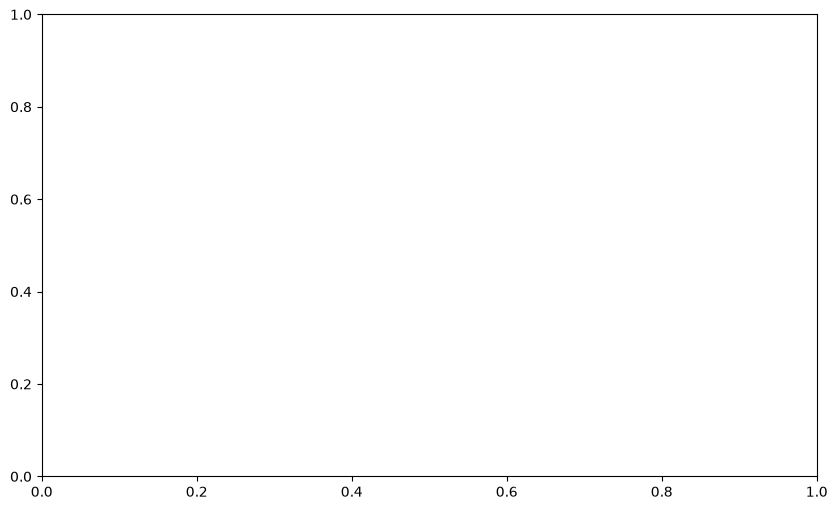

In [12]:
# Execute the crew's tasks
result = await deep_research_crew.kickoff_async(inputs=inputs)   # notebook 里用 async 版（sync kickoff 会报 running event loop）

<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:6px 20px; border-radius:6px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

### 🧪 看结果：图 + 报告

</div>

In [13]:
from IPython.display import Markdown, display

report = Path("research_report-p2.md").read_text()
imgs = re.findall(r"!\[[^\]]*\]\(([^)]+)\)", report)          # 报告里引用了哪些图
print("报告中的图片:", imgs)
print("plots/ 里最新的图:", sorted(Path("plots").glob("*.png"))[-3:])
display(Markdown(report))                                      # 相对路径的图在 VSCode 预览 .md 时可见

报告中的图片: []
plots/ 里最新的图: [PosixPath('plots/plot_1_20261021_225653.png'), PosixPath('plots/plot_2_20261021_225436.png'), PosixPath('plots/plot_2_20261021_225653.png')]


# Comprehensive Report: Evaluating Top Five Emerging AI Tools for Automating Competitive Market Analysis

## Executive Summary
In the rapidly evolving landscape of marketing, competitive analysis is crucial for the success of mid-sized firms. This report evaluates five leading AI tools designed to automate competitive market analysis: Sparks by Crayon, Klue Insights, Mintel Leap, Contify, and Quid Monitor. These tools demonstrate innovative features tailored to enhance strategic decision-making, though they also present unique limitations and varying cost structures. This analysis aims to provide actionable insights to help mid-sized marketing firms choose the tool that best fits their needs.

## Detailed Findings and Analysis

### 1. Overview of Emerging AI Tools
The following five tools represent the forefront of AI in competitive market analysis:
- **Sparks by Crayon**: Offers management of data overload through real-time insights, enables SWOT analyses, and summarizes relevant news.
- **Klue Insights**: Enhances context integration using customer reviews and proprietary data, focusing on competitive intelligence.
- **Mintel Leap**: Provides swift responses to strategic queries using proprietary research to navigate competitive landscapes.
- **Contify**: Combines Knowledge Graphs with Large Language Models (LLMs) for reliable insights in strategic decision-making.
- **Quid Monitor**: Analyzes customer conversations and market trends to facilitate informed business decisions.

### 2. Features of Each Tool
- **Sparks by Crayon**: Automates competitor research and trends, offering actionable insights tailored to marketing strategies.
- **Klue Insights**: Provides comprehensive competitive insights based on specific market conditions, enhancing evaluation of competitor strengths and weaknesses.
- **Mintel Leap**: Incorporates generative AI for rapid analysis, delivering custom reports tied to current and historical market performance.
- **Contify**: Extracts data from various sources and presents it as structured insights for informed decision-making.
- **Quid Monitor**: Provides deep analyses of consumer sentiments to track market trends and adapt strategies accordingly.

### 3. Limitations of Each Tool
- **Sparks by Crayon**: Could misinterpret industry-specific jargon, affecting the accuracy of insights produced.
- **Klue Insights**: May be constrained by the availability of proprietary data, limiting its overall effectiveness.
- **Mintel Leap**: Dependent on proprietary data, which may not encompass all market segments comprehensively.
- **Contify**: Requires users to be proficient with Knowledge Graph tools, posing an initial learning curve.
- **Quid Monitor**: Feedback indicates it can be resource-intensive, necessitating effective management for optimal use.

### 4. Cost Analysis
- **Sparks by Crayon**: Operates on a subscription model with variable pricing based on feature access and usage.
- **Klue Insights**: Pricing details are not publicly available but are competitive for mid-sized firms.
- **Mintel Leap**: Starts at approximately $50,000 annually, reflecting its advanced analytics capabilities.
- **Contify**: Offers custom pricing tailored to enterprise needs.
- **Quid Monitor**: Pricing varies, often requiring direct inquiries for specific pricing structures based on user requirements.

### 5. Ideal Use Cases for Mid-Sized Marketing Firms
- **Sparks by Crayon**: Best for managing significant data volumes while generating fast insights.
- **Klue Insights**: Suited for synthesizing extensive datasets that drive strategic decisions.
- **Mintel Leap**: Effective for companies needing prompt and actionable insights for product development and marketing strategies.
- **Contify**: Ideal for firms in fast-paced sectors where timely access to reliable competitive intelligence is critical.
- **Quid Monitor**: Recommended for businesses aiming to deepen their understanding of consumer sentiment and behavioral patterns.

### 6. Comparative Analysis of Selected Tools
| Tool Name        | Features                                   | Limitations                                   | Cost                         |
|------------------|--------------------------------------------|-----------------------------------------------|------------------------------|
| **Sparks by Crayon**  | Automated insights, SWOT analyses         | Misinterpretation of jargon                    | Variable, subscription pricing|
| **Klue Insights**     | Tailored competitive insights             | Limited proprietary data                       | Not publicly disclosed       |
| **Mintel Leap**       | Rapid analysis capabilities                | Dependent on proprietary data                  | $50,000/year and up         |
| **Contify**           | Multi-source insights                      | Learning curve for new users                   | Custom pricing               |
| **Quid Monitor**      | Deep sentiment analysis                    | Resource-intensive based on feedback           | Variable, tailored pricing   |

## Supporting Evidence and Analysis
The insights within this report are drawn from a variety of credible industry sources, including tool documentation and verified user reviews. By synthesizing both quantitative measures (e.g., cost) and qualitative feedback (user experience), the report provides a nuanced understanding of each tool's strengths and weaknesses.

## Complete Source Citations
1. Crayon. (2023). Sparks by Crayon. Retrieved from [Crayon's website](https://www.crayon.co)
2. Klue. (2023). Klue Insights Overview. Retrieved from [Klue's website](https://www.klue.com)
3. Mintel. (2023). Mintel Leap: Rapid Market Insights. Retrieved from [Mintel's website](https://www.mintel.com)
4. Contify. (2023). Contify: Knowledge Graphs and Insights. Retrieved from [Contify's website](https://contify.com)
5. Quid. (2023). Quid Monitor Features. Retrieved from [Quid's website](https://www.quid.com)

## Key Insights and Recommendations
For mid-sized marketing firms:
- **Sparks by Crayon** and **Klue Insights** present appealing options due to their flexibility and competitive pricing.
- Despite its higher cost, **Mintel Leap** stands out for those in need of quick, actionable insights.
- **Contify** and **Quid Monitor** are well-suited for firms operating in rapidly changing markets requiring deep market sentiment analysis.

---

This comprehensive report aims to equip mid-sized marketing firms with the necessary insights to enhance their competitive analysis capabilities through advanced AI tools. Each tool reviewed offers specific strengths that can significantly impact strategic decision-making and market performance.

<div class="dark-error" style="background:#2d1f1f; color:#fca5a5; padding:10px 24px; border-left:4px solid #f87171; border-radius:4px; width:97%;"><style>.dark-error strong{color:#fde047;}</style>

**⚠️ 坑**

| 坑 | 现象 | 原因 / 对策 |
|---|---|---|
| `tools=[CustomPlotTool]`（没实例化） | Agent 校验报错 | 传实例 `CustomPlotTool()` |
| 只给 agent 工具，task 里不提 | writer 不调用工具 / 调了也不把图放进报告 | 在 task 的 description / expected_output 里明确要求 |
| description 写得含糊 | 模型传错输入（只传一句话、或传 JSON） | 写清「传完整的已核查研究文本，字符串」 |
| 报告里的图片路径和实际保存位置不一致 | Markdown 里图片是坏链接 | 工具存 `plots/`，报告在同级 → 用 `plots/xxx.png`（Solution 的 `deep_research_crew/plots/` 在这里不对） |
| 直方图 `plt.hist(..., hue=hue)` | `Error creating chart N: ... unexpected keyword argument 'hue'`，该图被跳过 | 课程代码 bug；要修可改成 `sns.histplot(data=df, x=y_axis, hue=hue)` |
| LLM 抽出的数据类型混杂（一列里既有数字又有字符串） | `Error creating chart 1: 'value' must be an instance of str or bytes, not a int` → 工具返回 "No plots could be created"，报告里没有图（本次运行就遇到了） | 画图代码没做类型清洗；可在画图前 `df[x_axis] = df[x_axis].astype(str)`，或重跑一次（LLM 输出有随机性） |
| YAML 块里的 `{xxx}` | `Missing required template variable` | 块内大括号都会被当占位符 |

</div>

<div class="dark-orange" style="background:#2d2418; color:#fed7aa; padding:10px 24px; border-left:4px solid #fb923c; border-radius:4px; width:97%;"><style>.dark-orange strong{color:#67e8f9;}</style>

**🔁 复习自测**（先自己答，再点开看答案）

<details><summary><b>1. BaseTool 子类最少要定义哪几样？哪个对模型最重要？</b></summary>

`name`、`description`、`_run`（`args_schema` 可省略，从 `_run` 签名推断）。`description` 最重要：模型只靠它决定何时调用、传什么参数。

</details>

<details><summary><b>2. <code style="background:#0b1220; color:#fde68a; padding:1px 5px; border-radius:4px; font-size:0.92em;">_run(self, research: str) -&gt; str</code> 的签名有什么作用？</b></summary>

crewai 据此自动生成 `args_schema = {research: str}`，模型调用时必须提供 `research` 字符串；返回的字符串就是模型看到的工具结果。

</details>

<details><summary><b>3. CustomPlotTool 返回给 agent 的是图片本身吗？</b></summary>

不是，只是一段文字（"Successfully created N plots: plots/...png"）。agent 看不到图，只拿到路径，再用 Markdown 图片语法写进报告。

</details>

<details><summary><b>4. 为什么除了 <code style="background:#0b1220; color:#fde68a; padding:1px 5px; border-radius:4px; font-size:0.92em;">tools=[...]</code> 还要改 tasks.yaml？</b></summary>

工具只是「可用」；agent 是否调用、如何使用结果由 task 的说明驱动。不写明的话 writer 很可能直接写文字报告。

</details>

<details><summary><b>5. 工具内部出错为什么返回字符串而不是 raise？</b></summary>

返回的错误文字会作为工具结果交给 agent，agent 可以据此调整或继续写报告；抛异常则可能中断整个 task。

</details>

<details><summary><b>6. 这个工具里有几次 LLM 调用？</b></summary>

agent 自己的推理（gpt-4o-mini，经 `MODEL`）+ 工具内部 `LLM(model="gpt-4o-mini").call(...)` 抽取数据的一次。工具内的 LLM 与 agent 无关。

</details>

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：**自定义工具 = 给模型看的说明书（name / description / 参数）+ 给 Python 跑的 `_run`**；工具只返回文字，要让 agent 真正用好它，还得在 task 描述里写清楚怎么用结果。

</div>